In [31]:
################### Processing csv files to get points values! ########

from datetime import datetime, timedelta
import os
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import requests
import sys
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiPoint
from shapely.geometry import Point
import fiona
import contextily as ctx
from datetime import datetime
from sklearn.ensemble import RandomForestClassifier
import simplekml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pyproj import Proj, transform
import ast
from pyproj import Transformer
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject
from rasterio.enums import Resampling

from scipy.ndimage import binary_fill_holes
from scipy.ndimage import convolve
from scipy.ndimage import distance_transform_edt
from affine import Affine
from scipy.spatial import KDTree
from rasterio.mask import mask
from rasterio.features import shapes
from shapely.geometry import shape
from simplekml import Kml
from osgeo import gdal
import seaborn as sns
from sklearn.metrics import accuracy_score

In [2]:
def count_non_nan_values(array):
        """Counts non-NaN values in an array while ignoring non-numeric elements."""
        # Filter to keep only numeric data (e.g., ints and floats)
        numeric_values = [x for x in array if isinstance(x, (int, float))] 
        # Convert to NumPy array and count non-NaN values
        return np.sum(~np.isnan(np.array(numeric_values, dtype=float)))
    
def data_prep(path, file, cutoff=0, direction=0, cutlon=0, sensor = 1):
    ####### filter the data with 015042 index ######
    df = pd.read_csv(path + file)
    df['ID'] = range(0, len(df))  # Generates IDs starting from 1
    
    if sensor == 0:
        training_data = df[['lat', 'lon', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    else:
        training_data = df[['lat', 'lon', 'SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    
    predictor = []
    target = []
    coord = []
    # Loop through each (1585, 10) array in training_data
    print('training data is:')
    #print(training_data)
    print(training_data.shape)
    #for array in training_data:
        # Get rows where the target is not 'TZ'
    mask = training_data[:, 11] != 'MZ'
    
    predictor.append(training_data[mask, 2:11])  # First 9 columns
    target.append(training_data[mask, 11])       # Target column
    coord.append(training_data[mask, :2])
    
    # Convert to NumPy arrays if desired
    predictor = np.array(predictor)
    target = np.array(target)
    coord = np.array(coord)
    
    X = predictor.reshape(-1, 9)  # Shape: (5 * 1585, 9)
    y = target.reshape(-1)        # Shape: (5 * 1585,)
    coord = coord.reshape(-1, 2)
    ### cleanse the data by removing nan ####
    valid_indices = []

    # Loop through each row and check for NaN in the first column
    for i in range(X.shape[0]):
        if not np.isnan(X[i, 0]):
            valid_indices.append(i)
    
    # Create new X and y with only valid rows
    X = X[valid_indices]
    y = y[valid_indices]
    coord = coord[valid_indices]

    print('the size of dataset is:')
    print(X.shape[0])

    if cutoff:
        if direction > 0: ### keep the eastern side
            masklon = coord[:, 1] > cutlon
        else:
            masklon = coord[:, 1] <= cutlon
    
        X = X[masklon]
        y = y[masklon]
        coord = coord[masklon]
    
        print('the size of lon filtered dataset is:')
        print(X.shape[0])
        #print(X)
    
    return X, y, coord

In [12]:
def model_train_test(X, y):
    # Initialize the RandomForestClassifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    
    # Fit the model to the reshaped data
    model.fit(X, y)
    
    # After training, the model can be used for predictions or evaluation
    y_pred = model.predict(X)
    
    # Calculate accuracy by comparing the predictions with the true labels (y)
    accuracy = model.score(X, y)
    
    print(f"Training and testing using the whole dataset, accuracy is: {accuracy * 100:.2f}%")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_train, y_train)
    
    # Optionally, evaluate the model on the test set
    score = model.score(X_test, y_test)
    print(f"Testing using 20% of the whole dataset, accuracy is: {score*100:.2f}%")
    
    y_pred = model.predict(X_test)

    print("the number of elements for the prediction:")
    print(y_pred.shape[0])
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')
    
    return round(score, 2) 

In [32]:
def model_across_years(X, y, X_test, y_test):
    VZthreshold = 0.6
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, y)
    score = model.score(X_test, y_test)
    print(f"Testing across years, accuracy is: {score*100:.2f}%")
    
    # After training, the model can be used for predictions or evaluation
    y_proba = model.predict_proba(X_test)
    y_pred = model.predict(X_test)
    y_change = y_pred.copy()

    final_class_probs = np.max(y_proba, axis=1)

    vz_indices = (y_change == 'VZ') & (final_class_probs < VZthreshold)
    y_change[vz_indices] = 'TZ'
    score = model.score(X_test, y_test)
    
    y_change = np.array(y_change)
    y_test = np.array(y_test)

    # Calculate overall accuracy
    score = accuracy_score(y_test, y_change)
    return score
#     y_pred = model.predict(X_test)
#     cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
#     # Plot the confusion matrix
#     disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
#     disp.plot(cmap='Blues', values_format='.0f')

#     incorrect_indices = y_test != y_pred  # Boolean array where predictions are wrong
#     misclassified_data = coord_test[incorrect_indices]  # Coordinates of misclassified samples
#     misclassified_y_true = y_test[incorrect_indices]  # True values of misclassified samples
#     misclassified_y_pred = y_pred[incorrect_indices]  # Predicted values of misclassified samples
    
    # Output misclassified elements
#     print("\nMisclassified samples:")
    # for i in range(len(misclassified_data)):
    #     print(f"Coord: {misclassified_data[i]}, Predicted: {misclassified_y_pred[i]}, True: {misclassified_y_true[i]}")
    #return misclassified_data, misclassified_y_pred, misclassified_y_true
   

In [5]:
years = ['1985', '1994', '1999', '2003', '2009', '2013', '2018', '2023']

# Dictionaries to store data for each year
X_data = {}
y_data = {}
coord_data = {}
nan_indices = {}

for year in years:
    print(f"Processing year: {year}")
    folder_path = f'/Volumes/Malonelab/Research/Whitezone/Data/KML/{year}/'
    
    # Set the last parameter based on the year
    flag = 1 if int(year) < 2014 else 0
    
    X, y, coord = data_prep(folder_path, 'median.csv', 0, 0, 0, flag)
    X = X.astype(float)

    # Find NaN rows
    rows_with_nan = np.any(np.isnan(X), axis=1)
    indices_with_nan = np.where(rows_with_nan)[0]
    
    #print(f"indices with NaN in {year}: {indices_with_nan}")
    
    # Store results
    X_data[year] = X
    y_data[year] = y
    coord_data[year] = coord
    nan_indices[year] = indices_with_nan

Processing year: 1985
training data is:
(1579, 12)
the size of dataset is:
1439
Processing year: 1994
training data is:
(1619, 12)
the size of dataset is:
1488
Processing year: 1999
training data is:
(1577, 12)
the size of dataset is:
1444
Processing year: 2003
training data is:
(1581, 12)
the size of dataset is:
1448
Processing year: 2009
training data is:
(1584, 12)
the size of dataset is:
1452
Processing year: 2013
training data is:
(1586, 12)
the size of dataset is:
1455
Processing year: 2018
training data is:
(1584, 12)
the size of dataset is:
1462
Processing year: 2023
training data is:
(1583, 12)
the size of dataset is:
1476


Training model for year: 1985
Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 76.04%
the number of elements for the prediction:
288
Accuracy for 1985: 0.76
Training model for year: 1994
Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 74.83%
the number of elements for the prediction:
298
Accuracy for 1994: 0.75
Training model for year: 1999
Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 82.70%
the number of elements for the prediction:
289
Accuracy for 1999: 0.83
Training model for year: 2003
Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 82.41%
the number of elements for the prediction:
290
Accuracy for 2003: 0.82
Training model for year: 2009
Training and testing using the whole dataset, accuracy is:

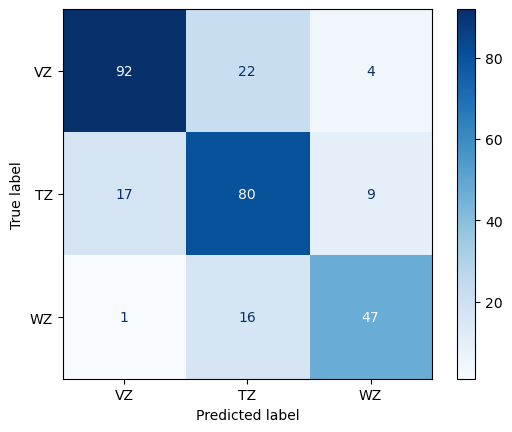

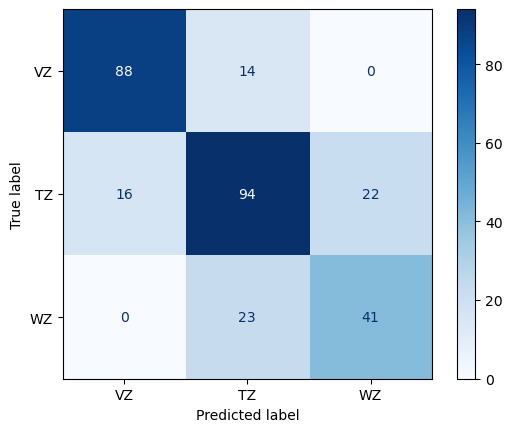

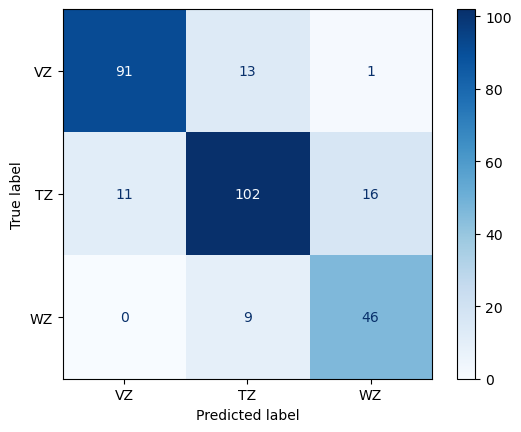

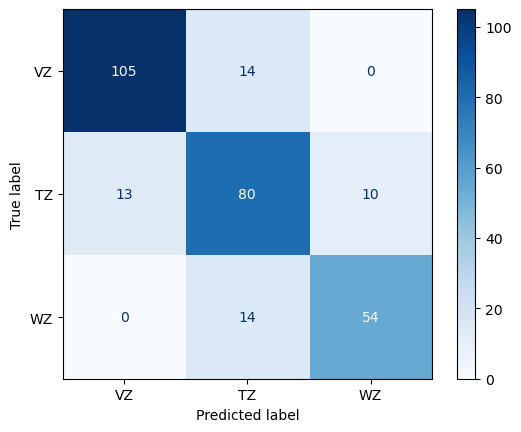

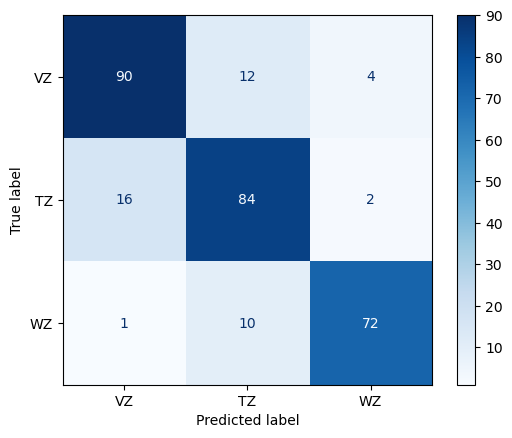

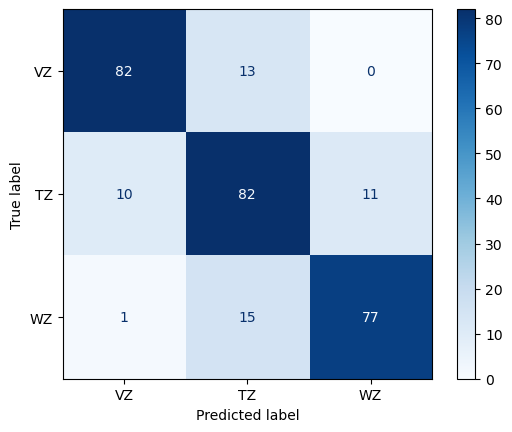

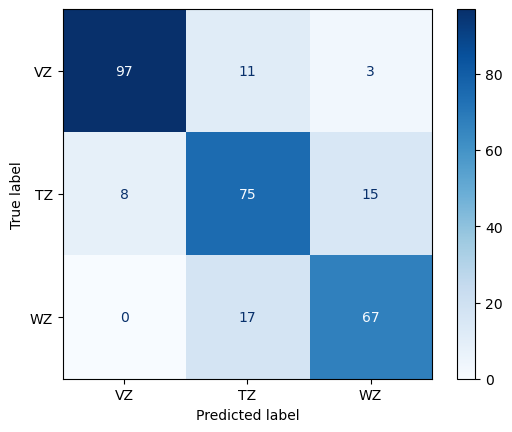

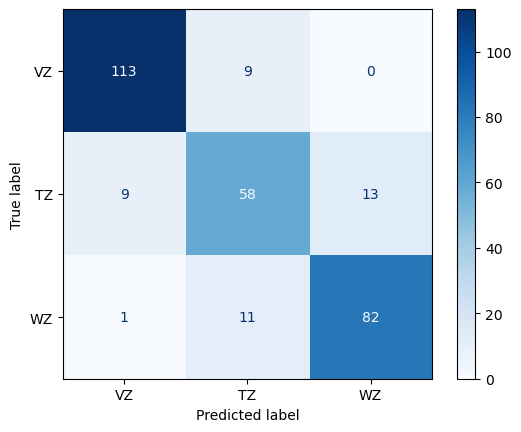

In [13]:
# Dictionary to store accuracy for each year
accuracy_by_year = {}

for year in years:
    X = X_data[year]
    y = y_data[year]
    
    print(f"Training model for year: {year}")
    accuracy = model_train_test(X, y)
    
    accuracy_by_year[year] = accuracy
    print(f"Accuracy for {year}: {accuracy}")

In [7]:
score = model_across_years(X_data['1985'], y_data['1985'], X_data['1994'], y_data['1994'])

Testing across years, accuracy is: 68.01%


In [33]:
n = len(years)
accuracy_matrix = np.zeros((n, n))

# Fill the diagonal with accuracy values for each year
for i, year in enumerate(years):
    accuracy_matrix[i, i] = accuracy_by_year[year]
    
for i in range(n):
    for j in range(i + 1, n):
        accuracy_matrix[i, j] = model_across_years(X_data[years[i]], y_data[years[i]], X_data[years[j]], y_data[years[j]]) 
        accuracy_matrix[j, i] = accuracy_matrix[i, j]  # Matrix is symmetric

Testing across years, accuracy is: 68.01%
Testing across years, accuracy is: 79.99%
Testing across years, accuracy is: 77.00%
Testing across years, accuracy is: 77.00%
Testing across years, accuracy is: 76.43%
Testing across years, accuracy is: 59.17%
Testing across years, accuracy is: 54.00%
Testing across years, accuracy is: 77.35%
Testing across years, accuracy is: 75.62%
Testing across years, accuracy is: 76.24%
Testing across years, accuracy is: 72.30%
Testing across years, accuracy is: 58.14%
Testing across years, accuracy is: 50.95%
Testing across years, accuracy is: 79.77%
Testing across years, accuracy is: 79.13%
Testing across years, accuracy is: 80.89%
Testing across years, accuracy is: 67.03%
Testing across years, accuracy is: 56.71%
Testing across years, accuracy is: 76.86%
Testing across years, accuracy is: 77.25%
Testing across years, accuracy is: 68.40%
Testing across years, accuracy is: 58.54%
Testing across years, accuracy is: 79.24%
Testing across years, accuracy is:

In [34]:
%matplotlib agg
# Create a heatmap for the accuracy matrix
# Mask the lower half of the matrix (i.e., set it to NaN)
fs=14
mask = np.triu(np.ones_like(accuracy_matrix, dtype=bool), k=1)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
# Create a heatmap for the upper triangular matrix (masked lower half)
plt.figure(figsize=(8, 6))
sns.heatmap(accuracy_matrix, annot=True, cmap="YlGnBu", xticklabels=years, yticklabels=years, cbar=True, mask=mask)

plt.title("Accuracy Matrix", fontsize=fs)
plt.xlabel("Target GE Years",fontsize=fs)
plt.ylabel("Reference GE Years",fontsize=fs)
plt.xticks(fontsize=fs)  # Increase font size for xticklabels
plt.yticks(fontsize=fs)  # Increase font size for yticklabels

# Adjust the colorbar label size
cbar = plt.gca().collections[0].colorbar
cbar.ax.tick_params(labelsize=fs)
plt.show()
plt.savefig('/Users/bz294/Documents/WhiteZone/Figure/temporal_accuracy_matrix_thd.tiff', format='tiff', dpi=300, bbox_inches='tight')

/var/folders/yw/3l8t5xh50v33m6zjql7k1rzsvhfd38/T/ipykernel_22849/1483239477.py:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# year = '1985'
# X_2018, y_2018, coord = data_prep('/Volumes/Malonelab/Research/Whitezone/Data/KML/' + year + '/', 'median.csv', 0, 0, 0, 1) ## mixing 2022 Mar and 2023 Feb
# X_2018 = X_2018.astype(float)
# rows_with_nan = np.any(np.isnan(X_2018), axis=1)
# indices_with_nan = np.where(rows_with_nan)[0]
# print("indices with nan are:")
# print(indices_with_nan)